# Classfication Problem

In [3]:
import numpy as np 
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Data Cleaning

In [4]:
df = pd.read_csv("exoplanets.csv")
print(df.shape)
print(df.head())

(9564, 49)
      kepid kepoi_name   kepler_name koi_disposition koi_pdisposition  \
0  10797460  K00752.01  Kepler-227 b       CONFIRMED        CANDIDATE   
1  10797460  K00752.02  Kepler-227 c       CONFIRMED        CANDIDATE   
2  10811496  K00753.01           NaN       CANDIDATE        CANDIDATE   
3  10848459  K00754.01           NaN  FALSE POSITIVE   FALSE POSITIVE   
4  10854555  K00755.01  Kepler-664 b       CONFIRMED        CANDIDATE   

   koi_score  koi_fpflag_nt  koi_fpflag_ss  koi_fpflag_co  koi_fpflag_ec  ...  \
0      1.000              0              0              0              0  ...   
1      0.969              0              0              0              0  ...   
2      0.000              0              0              0              0  ...   
3      0.000              0              1              0              0  ...   
4      1.000              0              0              0              0  ...   

   koi_steff_err2  koi_slogg  koi_slogg_err1  koi_slogg_err2  k

In [5]:
df.head()


,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [6]:
df["koi_disposition"].value_counts()

koi_disposition
FALSE POSITIVE    4840
CANDIDATE         2367
CONFIRMED         2357
Name: count, dtype: int64

In [7]:
df = df[df["koi_disposition"].isin(["CONFIRMED","FALSE POSITIVE"])].copy()

In [8]:
df["target"] = (df["koi_disposition"]=="CONFIRMED").astype(int)

In [12]:
df = df.dropna(subset=features).reset_index(drop=True)

In [13]:
df['koi_disposition'].value_counts()

koi_disposition
FALSE POSITIVE    4582
CONFIRMED         2356
Name: count, dtype: int64

In [10]:
skewed = ["koi_period", "koi_depth", "koi_prad", "koi_insol", "koi_model_snr"]
normal = ["koi_impact", "koi_duration", "koi_teq", "koi_steff",
          "koi_slogg", "koi_srad", "koi_kepmag"]

In [11]:
features = skewed + normal

In [14]:
X,y = df[features], df["target"]
print(X.isna().sum())

koi_period       0
koi_depth        0
koi_prad         0
koi_insol        0
koi_model_snr    0
koi_impact       0
koi_duration     0
koi_teq          0
koi_steff        0
koi_slogg        0
koi_srad         0
koi_kepmag       0
dtype: int64


In [15]:
print(y.value_counts(normalize=True))

target
0    0.660421
1    0.339579
Name: proportion, dtype: float64


In [16]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,stratify=y,random_state=42
)

In [17]:
log1p = FunctionTransformer(np.log1p,validate=False)

preprocess = ColumnTransformer([
    ("skew",Pipeline([("imp",SimpleImputer(strategy="median")),
                        ("log",log1p),
                        ("sc",StandardScaler())
    ]),skewed),
    ("norm",Pipeline([("imp",SimpleImputer(strategy="median")),
                        ("sc",StandardScaler())
    ]),normal),
])

In [18]:
rows_missing = X.isna().any(axis=1)
print(rows_missing.sum(), "of", len(X), f"({rows_missing.mean():.1%})")
print(y[rows_missing].value_counts())
print(y[~rows_missing].value_counts(normalize=True))

0 of 6938 (0.0%)
Series([], Name: count, dtype: int64)
target
0    0.660421
1    0.339579
Name: proportion, dtype: float64


In [19]:
print(X[skewed].min())

koi_period       0.241843
koi_depth        0.800000
koi_prad         0.080000
koi_insol        0.020000
koi_model_snr    0.000000
dtype: float64


# Classifiers

## KNN

In [20]:
models = {}

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV,StratifiedKFold

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

knn_pipe = Pipeline([("prep",preprocess),("clf",KNeighborsClassifier())])

knn_grid = GridSearchCV(
    knn_pipe,
    {"clf__n_neighbors":list(range(1,32,3)),
     "clf__weights":["uniform","distance"]},
     cv =cv,scoring="roc_auc",n_jobs=1,return_train_score=True
)

knn_grid.fit(X_train,y_train)
models["KNN"] = knn_grid.best_estimator_
print("KNN best:",knn_grid.best_params_,"CV AUC= %.4f" % knn_grid.best_score_)


KNN best: {'clf__n_neighbors': 19, 'clf__weights': 'distance'} CV AUC= 0.9573


## Decision Tree

In [22]:
from sklearn.tree import DecisionTreeClassifier

tree_full = Pipeline([("prep",preprocess),
                        ("clf",DecisionTreeClassifier(random_state=42))])

tree_full.fit(X_train,y_train)
models["Tree( unpruned)"] = tree_full

tree_pipe = Pipeline([("prep",preprocess),
                        ("clf",DecisionTreeClassifier(random_state = 42,
                                                    class_weight = "balanced"))])

tree_grid = GridSearchCV(
    tree_pipe,
    {"clf__max_depth":[3,4,5,6,8,10,15,None],
     "clf__min_samples_leaf":[1,5,10,20,50]},
     cv=cv,scoring="roc_auc",n_jobs=-1,return_train_score=True
)

tree_grid.fit(X_train,y_train)
models["Tree (tuned)"] = tree_grid.best_estimator_
print("Tree best:", tree_grid.best_params_,"CV AUC = %.4f" % tree_grid.best_score_)




Tree best: {'clf__max_depth': 15, 'clf__min_samples_leaf': 50} CV AUC = 0.9530


## SVM with RBF Kernels


In [23]:
from sklearn.svm import SVC

svm_pipe = Pipeline([("prep",preprocess),
                        ("clf",SVC(kernel="rbf",class_weight="balanced"))])

svm_grid = GridSearchCV(
    svm_pipe,
    {"clf__C":[0.1,1,10,100],
    "clf__gamma":["scale",0.01,0.05,0.1,0.5]},
    cv=cv,scoring="roc_auc",n_jobs=-1,return_train_score=True)
svm_grid.fit(X_train,y_train)
models["SVM (RBF)"] = svm_grid.best_estimator_
print("SVM best:",svm_grid.best_params_,"CV AUC = %.4f" %svm_grid.best_score_)


SVM best: {'clf__C': 100, 'clf__gamma': 'scale'} CV AUC = 0.9772


## Evaluation on the Test Set

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,accuracy_score,
                            precision_score,recall_score,f1_score,roc_auc_score,roc_curve)

def get_scores(m,X):
    if hasattr(m,"predict_proba"):
        return m.predict_proba(X)[:,1]
    return m.decision_function(X)

results = {}
for name , m in models.items():
    results[name] = dict(pred = m.predict(X_test),score=get_scores(m,X_test),
                        train_acc=accuracy_score(y_train,m.predict(X_train)))


In [25]:
def metrics_table(results):
    rows = []
    for name, r in results.items():
        rows.append({"Model":name,
                    "Train Acc":r["train_acc"],
                    "Test Acc": accuracy_score(y_test,r["pred"]),
                    "Precision": precision_score(y_test,r["pred"]),
                    "Recall": recall_score(y_test,r["pred"]),
                    "F1":f1_score(y_test,r["pred"]),
                    "ROC-AUC":roc_auc_score(y_test,r["pred"])
        })
    return pd.DataFrame(rows).set_index("Model").round(4)

In [26]:
table = metrics_table(results)
print(table)
table.to_csv("classification_metrics.csv")

                 Train Acc  Test Acc  Precision  Recall      F1  ROC-AUC
Model                                                                   
KNN                 1.0000    0.8970     0.7960  0.9363  0.8605   0.9065
Tree( unpruned)     1.0000    0.8775     0.7934  0.8641  0.8272   0.8743
Tree (tuned)        0.9063    0.8955     0.8099  0.9045  0.8546   0.8977
SVM (RBF)           0.9386    0.9186     0.8266  0.9618  0.8891   0.9291


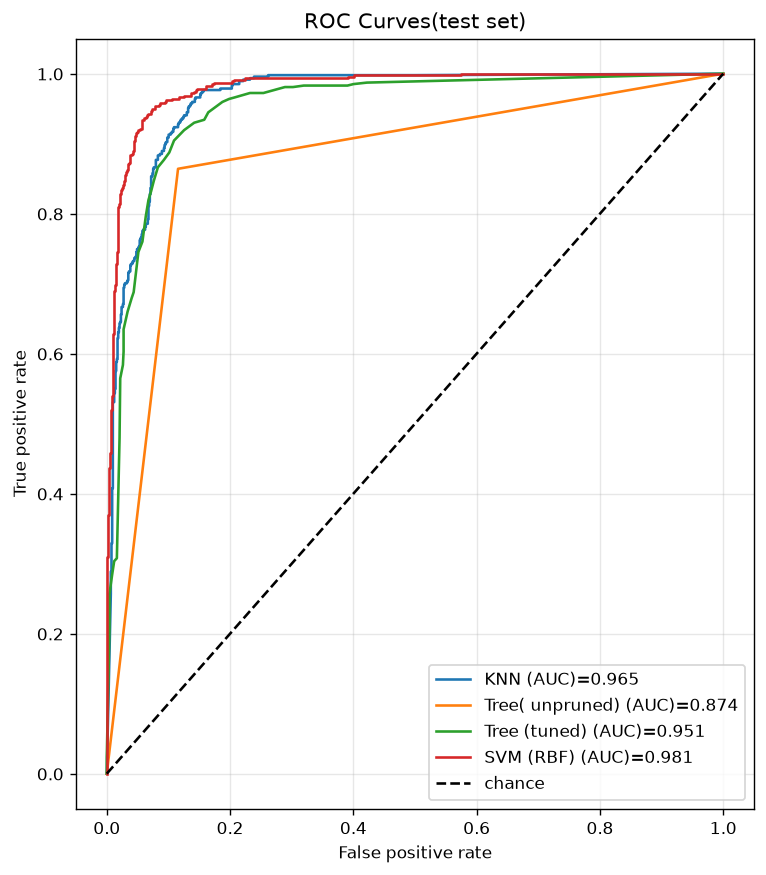

In [27]:
#ROC CURVES
plt.figure(figsize=(7,8))
for name, r in results.items():
    fpr,tpr , _  = roc_curve(y_test,r["score"])
    plt.plot(fpr,tpr,label=f"{name} (AUC)={roc_auc_score(y_test,r['score']):.3f}")
plt.plot([0,1],[0,1],"k--",label="chance")
plt.xlabel("False positive rate");
plt.ylabel("True positive rate");
plt.title("ROC Curves(test set)");
plt.legend();
plt.grid(alpha=.3)
plt.savefig("roc_curves.png",dpi=200);
plt.show()


### Overfitting and complexity plots

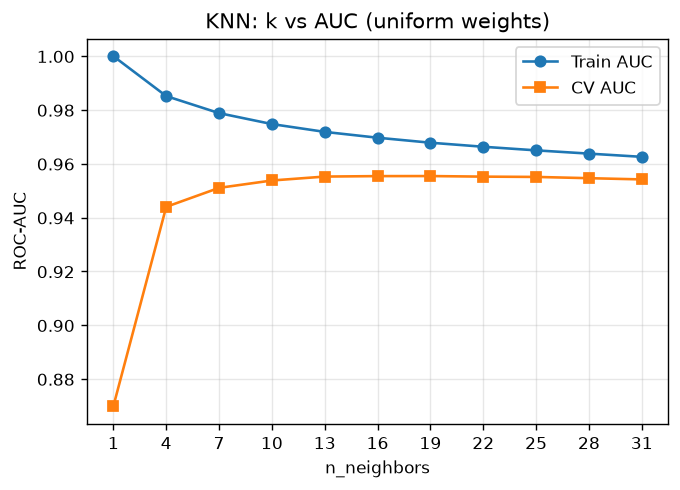

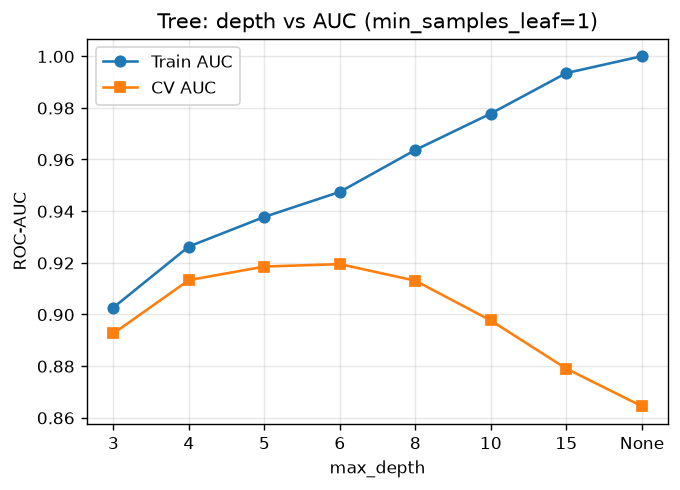

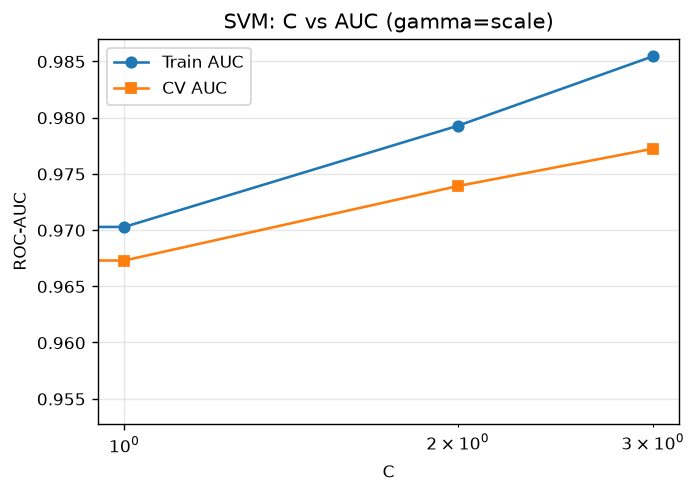

In [28]:
def plot_complexity(grid, param, fixed, title, fname, log_x=False):
    res = pd.DataFrame(grid.cv_results_)
    for k, v in fixed.items():
        res = res[res[k] == v]
    res = res.sort_values(param)
    x = res[param].map(lambda v:"None" if pd.isna(v) else str(v))
    plt.figure(figsize=(6, 4))
    plt.plot(x, res["mean_train_score"], "o-", label="Train AUC")
    plt.plot(x, res["mean_test_score"], "s-", label="CV AUC")
    if log_x: plt.xscale("log")
    plt.xlabel(param.replace("param_clf__", "")); plt.ylabel("ROC-AUC")
    plt.title(title); plt.legend(); plt.grid(alpha=.3)
    plt.savefig(fname, dpi=200); plt.show()

plot_complexity(knn_grid, "param_clf__n_neighbors", {"param_clf__weights": "uniform"},
                "KNN: k vs AUC (uniform weights)", "knn_complexity.png")
plot_complexity(tree_grid, "param_clf__max_depth", {"param_clf__min_samples_leaf": 1},
                "Tree: depth vs AUC (min_samples_leaf=1)", "tree_complexity.png")
plot_complexity(svm_grid, "param_clf__C", {"param_clf__gamma": "scale"},
                "SVM: C vs AUC (gamma=scale)", "svm_complexity.png", log_x=True)

## Deep CNN

Stopped at epoch 34, best val AUC = 0.9835


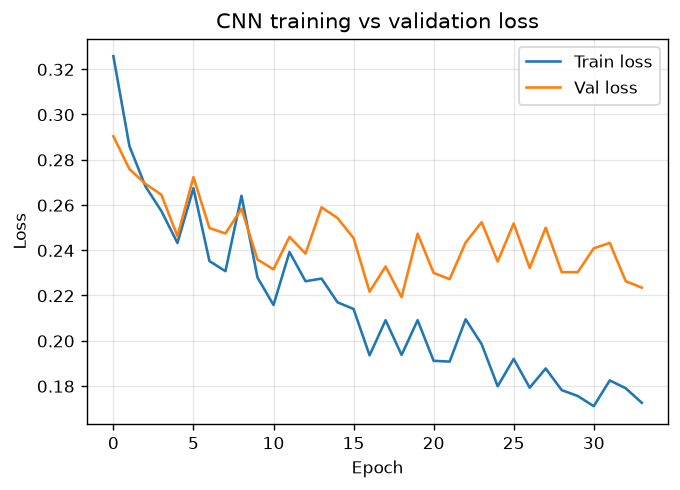

In [29]:
import torch, torch.nn as nn
from sklearn.base import clone

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)

prep = clone(preprocess).fit(X_train)
Xtr_all, Xte = prep.transform(X_train), prep.transform(X_test)
Xtr, Xva, ytr, yva = train_test_split(Xtr_all, y_train.values, test_size=0.15,
                                      stratify=y_train, random_state=42)

def T(a): return torch.tensor(a, dtype=torch.float32)
Xtr_t, Xva_t, Xte_t = [T(a).unsqueeze(1).to(dev) for a in (Xtr, Xva, Xte)]
ytr_t, yva_t = T(ytr).to(dev), T(yva).to(dev)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, 3, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(128 * 12, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 1))
    def forward(self, x): return self.net(x).squeeze(1)

model = CNN().to(dev)
pos_w = torch.tensor((ytr == 0).sum() / (ytr == 1).sum(), dtype=torch.float32, device=dev)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

best_auc, best_state, patience, bad = 0, None, 15, 0
hist = {"train_loss": [], "val_loss": [], "val_auc": []}
for epoch in range(200):
    model.train()
    perm = torch.randperm(len(Xtr_t), device=dev)
    for i in range(0, len(perm), 128):
        idx = perm[i:i+128]
        opt.zero_grad()
        loss = loss_fn(model(Xtr_t[idx]), ytr_t[idx]); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        tl = loss_fn(model(Xtr_t), ytr_t).item()
        vlogit = model(Xva_t); vl = loss_fn(vlogit, yva_t).item()
    va = roc_auc_score(yva, vlogit.cpu().numpy())
    hist["train_loss"].append(tl); hist["val_loss"].append(vl); hist["val_auc"].append(va)
    if va > best_auc:
        best_auc, bad = va, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= patience: break
print(f"Stopped at epoch {epoch+1}, best val AUC = {best_auc:.4f}")

model.load_state_dict(best_state); model.eval()
with torch.no_grad():
    te_score = torch.sigmoid(model(Xte_t)).cpu().numpy()
    tr_pred = (torch.sigmoid(model(T(Xtr_all).unsqueeze(1).to(dev))).cpu().numpy() > 0.5).astype(int)

results["CNN"] = dict(pred=(te_score > 0.5).astype(int), score=te_score,
                      train_acc=accuracy_score(y_train, tr_pred))

plt.figure(figsize=(6, 4))
plt.plot(hist["train_loss"], label="Train loss"); plt.plot(hist["val_loss"], label="Val loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=.3)
plt.title("CNN training vs validation loss"); plt.savefig("cnn_loss.png", dpi=200); plt.show()